Tugas Machine Learning 13

13.1 Persiapan Library

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


13.2 Import Dataset

In [ ]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

if os.path.isdir("dataset/train") and os.path.isdir("dataset/val"):
    print("Memakai dataset lokal")
    train_ds = keras.utils.image_dataset_from_directory(
        "dataset/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED)
    val_ds = keras.utils.image_dataset_from_directory(
        "dataset/val", image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
else:
    print("Folder dataset/ tidak ditemukan -> memakai flower_photos")
    url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
    data_dir = keras.utils.get_file("flower_photos", origin=url, untar=True)
    data_dir = os.path.join(os.path.dirname(data_dir), "flower_photos") \
        if not os.path.isdir(os.path.join(data_dir, "daisy")) else data_dir
    train_ds = keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="training", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE)
    val_ds = keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="validation", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

# Simpan SEBELUM .map(), karena atribut class_names hilang setelah .map()
class_names = train_ds.class_names
jumlah_kelas = len(class_names)
print("Kelas:", class_names)

Folder dataset/ tidak ditemukan -> memakai flower_photos
228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Found 3670 files belonging to 1 classes.
Using 2936 files for training.
Found 3670 files belonging to 1 classes.
Using 734 files for validation.
Kelas: ['flower_photos']


13.3 Preprocessing

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (train_ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
            .cache().shuffle(1000).prefetch(AUTOTUNE))
val_ds = (val_ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
          .cache().prefetch(AUTOTUNE))

13.4 Training Model (Transfer Learning dengan MobileNetV2)

In [ ]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,),
                         include_top=False, weights="imagenet")
base_model.trainable = False  # Feature extraction: bekukan bobot pre-trained

# Augmentasi hanya aktif saat training (otomatis nonaktif saat evaluasi)
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
])

model = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

history = model.fit(train_ds, validation_data=val_ds, epochs=15)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


92/92 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 134s 990ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 83s 899ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 144s 917ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 912ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 145s 944ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 139s 912ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.00

13.5 Evaluasi

In [ ]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc:.3f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 625ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00
Akurasi Validasi: 0.000


13.6 Visualisasi

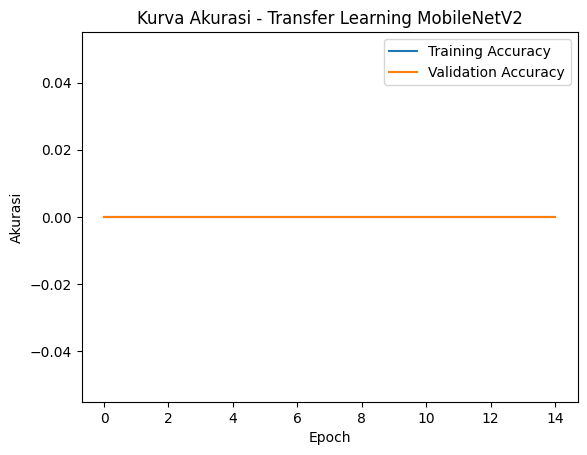

In [ ]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend()
plt.show()

13.7 Praktikum

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3445s 20us/step
(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)
Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 69s 86ms/step - accuracy: 0.4286 - loss: 1.5817 - val_accuracy: 0.5292 - val_loss: 1.3224
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 67s 86ms/step - accuracy: 0.5609 - loss: 1.2378 - val_accuracy: 0.5770 - val_loss: 1.1951
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 81s 85ms/step - accuracy: 0.6185 - loss: 1.0864 - val_accuracy: 0.6140 - val_loss: 1.1118
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.6533 - loss: 0.9930 - val_accuracy: 0.6486 - val_loss: 1.0060
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 81s 82ms/step - accuracy: 0.6788 - loss: 0.9240 - val_accuracy: 0.6597 - val_loss: 0.9831
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.6991 - loss: 0.8656 - val_accuracy: 0.6620 - val_loss: 0.9681
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 65s 83ms/step - accuracy: 0.7160 - loss: 0.8226 - val_accuracy:

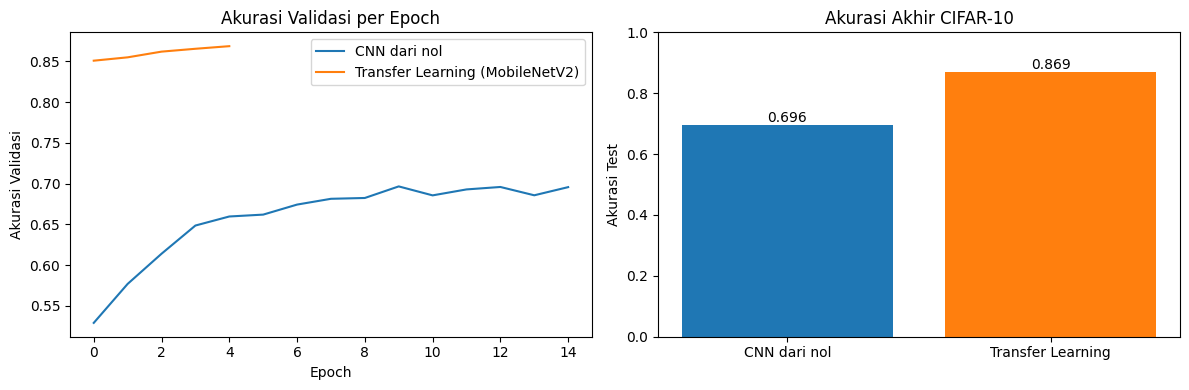

Model                          Parameter   Akurasi Test
CNN dari nol                     167,562          0.696
Transfer Learning              2,423,242          0.869


In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

# Normalisasi 0-1 khusus untuk CNN dari nol
x_train_n = x_train.astype("float32") / 255.0
x_test_n = x_test.astype("float32") / 255.0

model_cnn = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model_cnn.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

hist_cnn = model_cnn.fit(x_train_n, y_train, epochs=15, batch_size=64,
                         validation_data=(x_test_n, y_test))
cnn_loss, cnn_acc = model_cnn.evaluate(x_test_n, y_test, verbose=0)
print(f"Akurasi Test CNN: {cnn_acc:.3f}")

TL_SIZE = (96, 96)

def siapkan(x, y, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(10000, seed=SEED)
    ds = ds.batch(64)
    ds = ds.map(lambda a, b: (preprocess_input(tf.image.resize(tf.cast(a, tf.float32), TL_SIZE)), b),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_c10 = siapkan(x_train, y_train, True)
test_c10 = siapkan(x_test, y_test, False)

base_c10 = MobileNetV2(input_shape=TL_SIZE + (3,), include_top=False, weights="imagenet")
base_c10.trainable = False

model_tl = keras.Sequential([
    keras.Input(shape=TL_SIZE + (3,)),
    base_c10,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax"),
])
model_tl.compile(optimizer="adam",
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])

hist_tl = model_tl.fit(train_c10, validation_data=test_c10, epochs=5)
tl_loss, tl_acc = model_tl.evaluate(test_c10, verbose=0)
print(f"Akurasi Test Transfer Learning: {tl_acc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(hist_cnn.history["val_accuracy"], label="CNN dari nol")
ax[0].plot(hist_tl.history["val_accuracy"], label="Transfer Learning (MobileNetV2)")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Akurasi Validasi")
ax[0].set_title("Akurasi Validasi per Epoch"); ax[0].legend()

ax[1].bar(["CNN dari nol", "Transfer Learning"], [cnn_acc, tl_acc], color=["tab:blue", "tab:orange"])
ax[1].set_ylim(0, 1); ax[1].set_ylabel("Akurasi Test")
ax[1].set_title("Akurasi Akhir CIFAR-10")
for i, v in enumerate([cnn_acc, tl_acc]):
    ax[1].text(i, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout(); plt.show()

print(f"{'Model':<28}{'Parameter':>12}{'Akurasi Test':>15}")
print(f"{'CNN dari nol':<28}{model_cnn.count_params():>12,}{cnn_acc:>15.3f}")
print(f"{'Transfer Learning':<28}{model_tl.count_params():>12,}{tl_acc:>15.3f}")